In [1]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.cross_decomposition import PLSCanonical


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
file_ids = list(range(0, 12+1))
# file_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
# file_ids = [0]
plot_id = 0

bhl_selection = ['still', 'walk', 'front-groom', 'back-groom', 'abdomen-move']

dims = 4

In [4]:
path = os.path.join(read_utils.get_data_path(), 'brain')

# read
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_datas(path, file_ids)

# clear nan values
for i in range(len(file_ids)):
	mask = markers[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	markers[i] = markers[i][mask]
	states[i] = states[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

# preprocess
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]
traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]
#markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]

In [5]:
for idx in range(len(states)):
	states[idx] = states[idx].reindex(columns=['still', 'walk', 'front-groom', 'back-groom', 'abdomen-move'])

In [6]:
plot_idx = file_ids.index(plot_id)

In [7]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans) = train_utils.get_manifolds_plsc(traces,
												  [s[bhl_selection] for s in states],
												  scale=(False, False),
												  n_ls=dims)

In [8]:
save = True

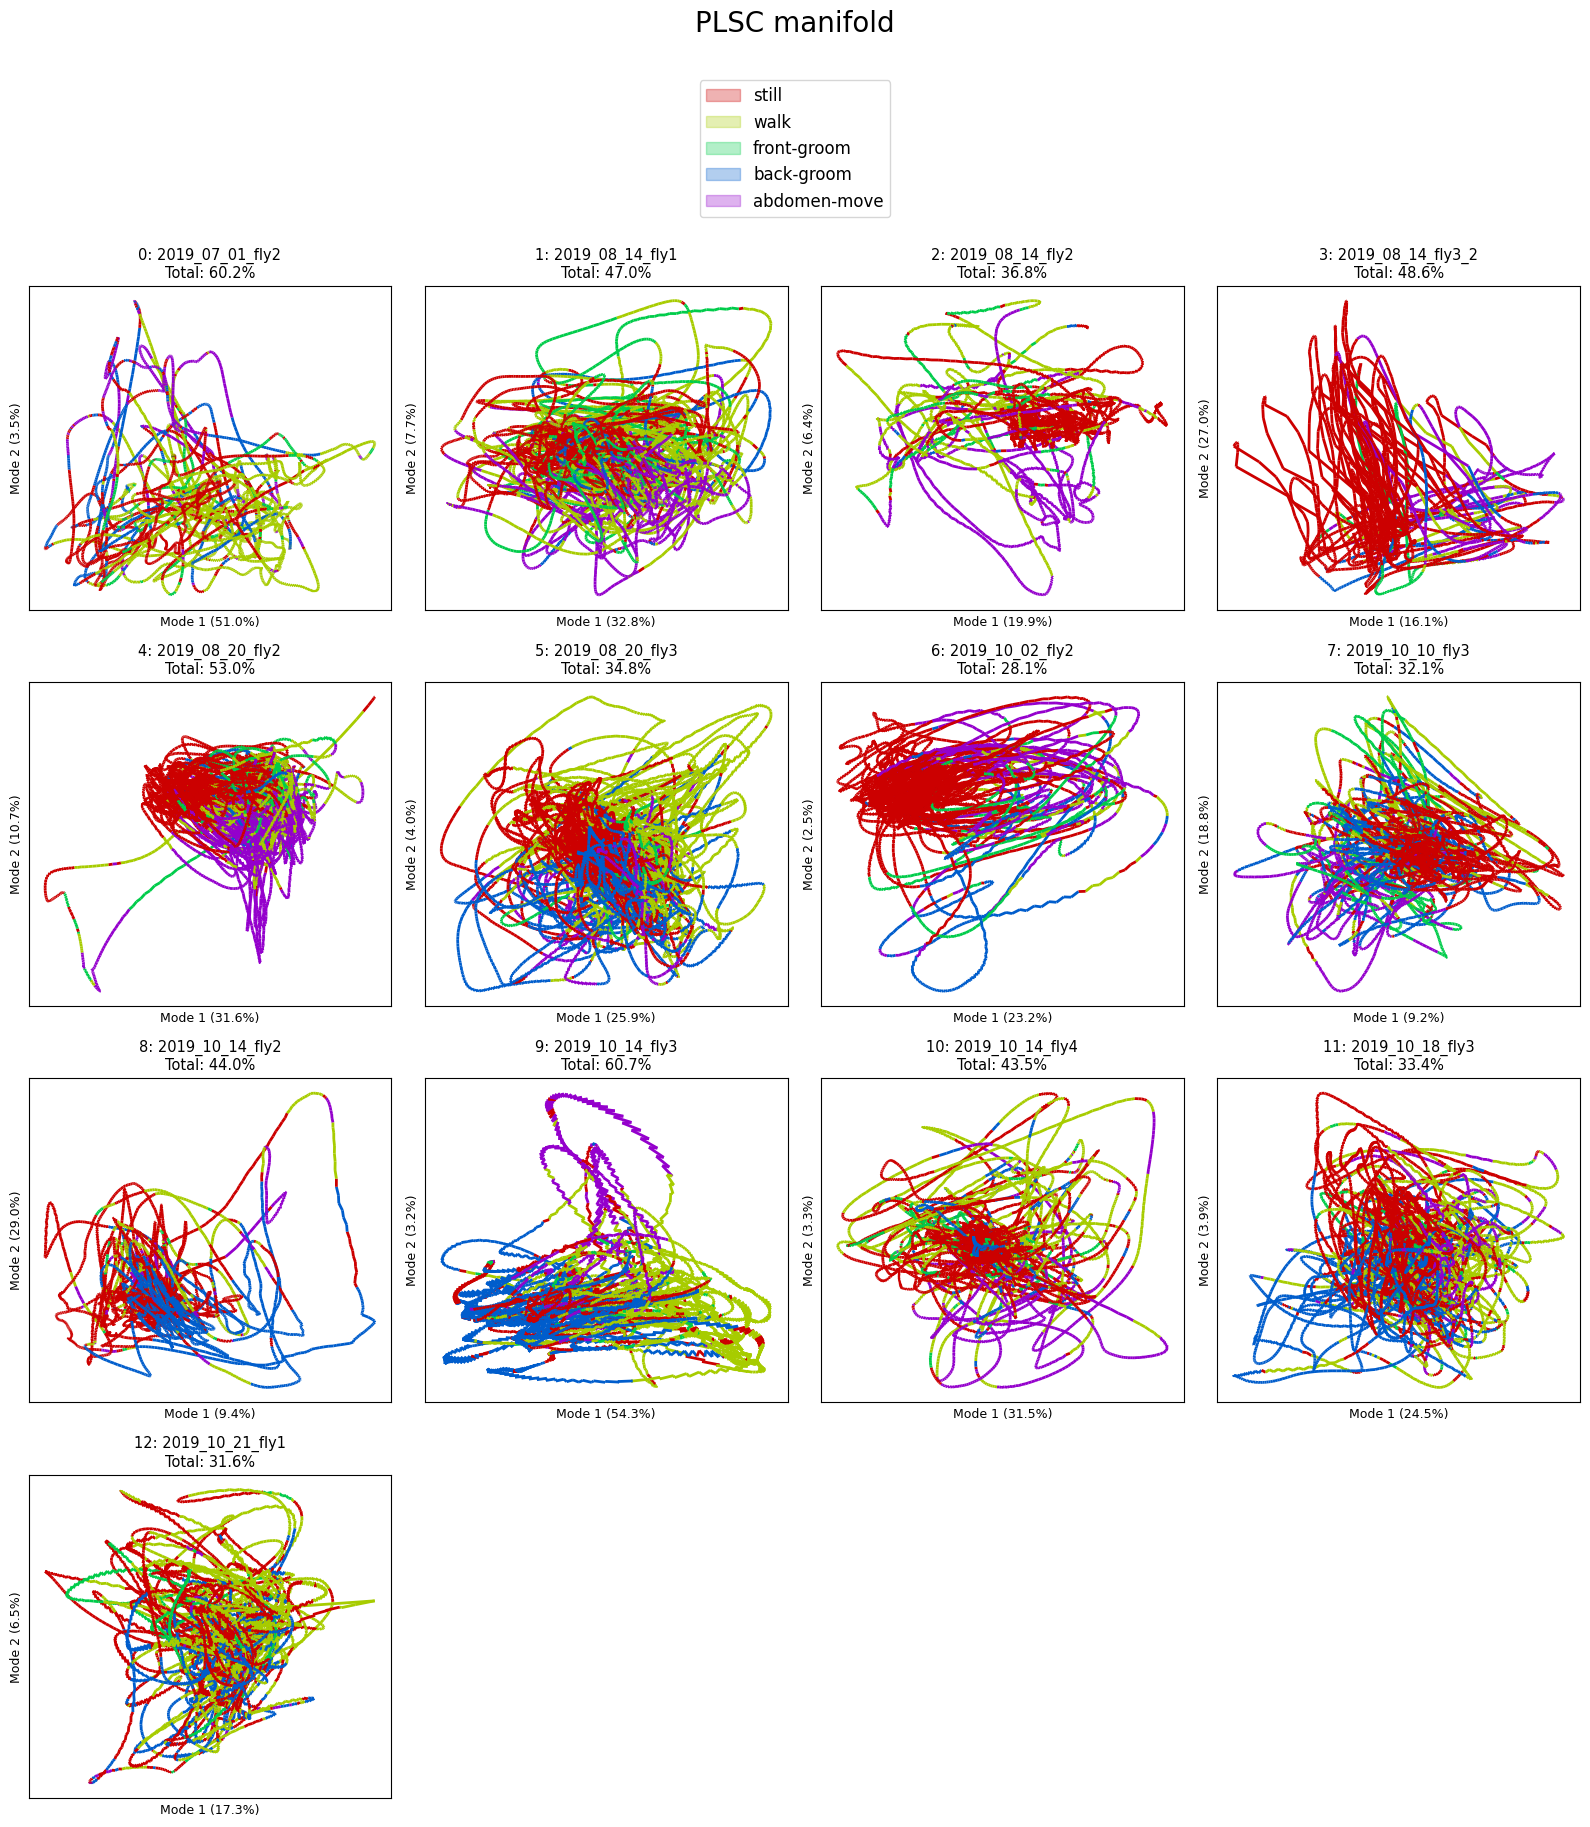

42.6%


In [9]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, states,
						  [vx for vx in vars_expl_mans], None,
						  title='PLSC manifold', top_space=2.5,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-PLSC' if save else None)

In [10]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 							 modes_manifold, states,
# 							 [vx[:3] for vx in vars_expl_mans], None,
# 							 title='PLSC manifolds (100s high-pass filter)', top_space=3,
# 							 save_path=f'../../out/plots/manifolds/{dims}-dim-PLSC_3d' if save else None)

In [11]:
for i, trace in enumerate(traces):
	print(np.mean(trace.values, axis=0))

[ 2.37185867e-05  1.04967881e-05 -1.72755488e-06 ...  8.11570176e-06
  8.54363303e-06  1.02351925e-05]
[-1.80297369e-06  3.02665198e-05 -5.31332765e-06 ... -1.50346096e-08
  2.09294611e-05 -2.17224570e-05]
[-2.47045681e-05  9.38844621e-05  1.08397257e-04 ...  1.61152178e-05
  1.28445804e-05  7.75366618e-06]
[-6.99085150e-05 -3.36374042e-05  7.87121767e-05 ... -1.14272440e-05
 -7.04881950e-05  5.21399589e-05]
[-2.10522827e-04 -1.29863583e-04 -1.97200572e-04 -2.10153632e-04
 -2.57761756e-04 -1.51589393e-04 -2.08322665e-04 -1.41747443e-04
 -3.77318334e-04 -1.03474285e-04 -2.57781011e-04 -3.37957808e-04
 -2.16973836e-04 -1.20542404e-04 -1.30678219e-04 -1.10101478e-04
  1.62759545e-05 -1.73857437e-04 -7.77820746e-05 -7.42820953e-05
 -3.17062024e-04 -3.12328765e-04 -2.77342558e-04 -1.59463623e-04
 -5.95768371e-05 -1.50942274e-04 -4.95224330e-05 -1.18319521e-04
 -2.04051159e-04 -2.24603556e-04 -1.55857306e-04 -1.27883227e-04
 -1.89646775e-04 -1.21821666e-04 -2.46636254e-04 -5.63355553e-05
 -8

In [12]:
traces_residual = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip(traces, recos_manifold)]

for i, trace in enumerate(traces_residual):
	print(np.mean(trace.values, axis=0))

[-5.43215102e-20 -7.06179632e-20  6.51858122e-20 ...  1.62964530e-20
  2.79755777e-19 -4.34572081e-20]
[-2.47259228e-20  2.90893210e-20 -2.03625247e-20 ... -1.30901944e-20
 -3.19982531e-20  0.00000000e+00]
[ 2.89459790e-20 -7.23649475e-20  7.23649475e-20 ...  4.70372159e-20
 -5.06554633e-20  1.33875153e-19]
[-3.96649884e-20  1.98324942e-19 -3.96649884e-20 ...  1.38827459e-19
  1.38827459e-19 -3.96649884e-20]
[-5.13801844e-20 -3.08281106e-20  8.56336407e-21 -3.76788019e-20
  3.08281106e-20 -7.53576038e-20 -5.48055300e-20 -2.91154378e-20
 -1.37013825e-20 -5.48055300e-20 -3.76788019e-20  2.74027650e-20
 -1.04473042e-19  3.42534563e-20 -2.56900922e-20 -3.93914747e-20
  3.76788019e-20  4.79548388e-20 -5.99435485e-21  3.68224655e-20
 -3.76788019e-20 -1.43864516e-19 -6.85069125e-20  1.19887097e-20
 -1.13036406e-19 -4.62421660e-20  2.05520738e-20 -1.88394009e-20
  3.42534563e-21  6.16562213e-20  2.39774194e-20 -8.90589863e-20
 -1.57565899e-19 -4.36731567e-20 -6.85069125e-21 -4.11041475e-20
 -6